In [7]:
%pip -q install lightgbm==4.6.0 PyYAML==6.0.2

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import lightgbm as lgb
import yaml
import joblib

from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

RANDOM_STATE = 42
FEATURE_LAG = 2

print("Библиотеки подключены")

Библиотеки подключены


In [9]:
data_path = Path("/content/NBK_BNS_variant6_2016_2025.csv")

assert data_path.exists(), "Проверь название загруженного CSV."

data = pd.read_csv(data_path, encoding="utf-8-sig")

data["month"] = pd.to_datetime(
    data["month"], format="%Y-%m", errors="raise"
)

data = data.sort_values("month").reset_index(drop=True)

numeric_columns = data.columns.drop("month")

data[numeric_columns] = data[numeric_columns].apply(
    pd.to_numeric, errors="raise"
)

assert np.isfinite(data[numeric_columns].to_numpy()).all()

assert pd.DatetimeIndex(data["month"]).equals(
    pd.date_range("2016-01-01", "2025-12-01", freq="MS")
)

print("Проверено: 120 последовательных месяцев")

Проверено: 120 последовательных месяцев


In [10]:
TRAIN_END = pd.Timestamp("2022-12-01")
VALID_END = pd.Timestamp("2024-06-01")

development = data[data["month"] <= VALID_END].copy()
test_locked = data[data["month"] > VALID_END].copy()

targets = {
    "business": "Y_business_change_pp",
    "households": "Y_households_change_pp",
}

group_names = {
    "business": "Юридические лица",
    "households": "Физические лица, включая ИП",
}

assert len(development) == 102
assert len(test_locked) == 18

print("Для разработки доступны train и validation.")
print("Test отложен до четвёртого этапа.")

Для разработки доступны train и validation.
Test отложен до четвёртого этапа.


In [11]:
def make_macro_features(frame, lag=2):
    frame = frame.sort_values("month").reset_index(drop=True)
    features = pd.DataFrame(index=frame.index)

    inflation = frame["inflation_yoy_pct"]
    base = frame["base_rate_pct"]
    change = inflation.diff().round(10)

    features["inflation_yoy_lag2"] = inflation.shift(lag)
    features["inflation_mom_lag2"] = (
        frame["inflation_mom_pct"].shift(lag)
    )

    features["inflation_change_lag2"] = change.shift(lag)
    features["inflation_up_lag2"] = (
        change.clip(lower=0).shift(lag)
    )
    features["inflation_down_lag2"] = (
        change.clip(upper=0).shift(lag)
    )

    features["base_rate_lag2"] = base.shift(lag)
    features["base_change_lag2"] = base.diff().shift(lag)

    features["inflation_mean3_lag2"] = (
        inflation.rolling(3).mean().shift(lag)
    )
    features["inflation_std3_lag2"] = (
        inflation.rolling(3).std().shift(lag)
    )

    features["real_base_proxy_lag2"] = (
        base - inflation
    ).shift(lag)

    return features

print("Макроэкономические признаки подготовлены")

Макроэкономические признаки подготовлены


In [12]:
def make_features(frame, group, lag=2):
    frame = frame.sort_values("month").reset_index(drop=True)
    features = make_macro_features(frame, lag)

    rate = frame[f"loan_{group}_pct"]
    change = frame[targets[group]]

    features["loan_rate_lag2"] = rate.shift(lag)
    features["loan_change_lag2"] = change.shift(lag)
    features["loan_change_lag3"] = change.shift(lag + 1)

    features["loan_change_mean3_lag2"] = (
        change.rolling(3).mean().shift(lag)
    )
    features["loan_change_std3_lag2"] = (
        change.rolling(3).std().shift(lag)
    )

    features["loan_base_spread_lag2"] = (
        rate - frame["base_rate_pct"]
    ).shift(lag)

    return features

print("Функция создания 16 признаков готова")

Функция создания 16 признаков готова


In [13]:
datasets = {}

for group, target in targets.items():
    X = make_features(development, group, FEATURE_LAG)
    usable = X.notna().all(axis=1)

    train_mask = usable & (development["month"] <= TRAIN_END)
    valid_mask = usable & (development["month"] > TRAIN_END)

    datasets[group] = {
        "X_train": X.loc[train_mask].copy(),
        "y_train": development.loc[train_mask, target].copy(),
        "X_valid": X.loc[valid_mask].copy(),
        "y_valid": development.loc[valid_mask, target].copy(),
        "dates_valid": development.loc[valid_mask, "month"].copy(),
    }

    assert train_mask.sum() == 80
    assert valid_mask.sum() == 18

    print(
        group_names[group],
        "| Train:", train_mask.sum(),
        "| Validation:", valid_mask.sum(),
        "| Признаков:", X.shape[1]
    )

Юридические лица | Train: 80 | Validation: 18 | Признаков: 16
Физические лица, включая ИП | Train: 80 | Validation: 18 | Признаков: 16


In [14]:
baseline_columns = {
    "symmetric": [
        "loan_change_lag2",
        "base_change_lag2",
        "inflation_change_lag2",
    ],
    "asymmetric": [
        "loan_change_lag2",
        "base_change_lag2",
        "inflation_up_lag2",
        "inflation_down_lag2",
    ],
}

baseline_models = {}
predictions = {}

for group, parts in datasets.items():
    baseline_models[group] = {}

    predictions[group] = {
        "zero_change": np.zeros(len(parts["y_valid"]))
    }

    for name, columns in baseline_columns.items():
        X_train = sm.add_constant(
            parts["X_train"][columns],
            has_constant="add"
        )
        X_valid = sm.add_constant(
            parts["X_valid"][columns],
            has_constant="add"
        )

        assert np.linalg.matrix_rank(
            X_train.to_numpy()
        ) == X_train.shape[1]

        model = sm.OLS(parts["y_train"], X_train).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": 3, "use_correction": True},
            use_t=False
        )

        baseline_models[group][name] = model
        predictions[group][name] = model.predict(X_valid)

print("Регрессии и прогноз «без изменения ставки» готовы")

Регрессии и прогноз «без изменения ставки» готовы


In [15]:
parameter_candidates = [
    {"num_leaves": 3, "max_depth": 2, "min_child_samples": 15},
    {"num_leaves": 4, "max_depth": 2, "min_child_samples": 20},
    {"num_leaves": 5, "max_depth": 3, "min_child_samples": 15},
    {"num_leaves": 7, "max_depth": 3, "min_child_samples": 20},
]

common_params = {
    "objective": "regression",
    "metric": "rmse",
    "n_estimators": 1000,
    "learning_rate": 0.03,
    "reg_lambda": 1.0,
    "random_state": RANDOM_STATE,
    "n_jobs": 1,
    "verbosity": -1,
    "deterministic": True,
    "force_col_wise": True,
    "importance_type": "gain",
}

print("Подготовлено 4 варианта параметров")

Подготовлено 4 варианта параметров


In [16]:
boosting_models = {}
best_settings = {}
search_rows = []

for group, parts in datasets.items():
    best_rmse = np.inf

    for number, candidate in enumerate(parameter_candidates, start=1):
        model = lgb.LGBMRegressor(
            **common_params,
            **candidate
        )

        model.fit(
            parts["X_train"],
            parts["y_train"],
            eval_set=[(parts["X_valid"], parts["y_valid"])],
            eval_metric="rmse",
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=50,
                    first_metric_only=True,
                    verbose=False
                )
            ]
        )

        prediction = model.predict(
            parts["X_valid"],
            num_iteration=model.best_iteration_
        )

        rmse = float(np.sqrt(
            mean_squared_error(parts["y_valid"], prediction)
        ))

        search_rows.append({
            "group": group,
            "candidate": number,
            **candidate,
            "best_iteration": int(model.best_iteration_),
            "validation_rmse": rmse,
        })

        if rmse < best_rmse:
            best_rmse = rmse
            boosting_models[group] = model
            predictions[group]["lightgbm"] = prediction

            best_settings[group] = {
                **candidate,
                "best_iteration": int(model.best_iteration_),
                "validation_rmse": rmse,
            }

    print(group_names[group], "— обучение завершено")

search_results = pd.DataFrame(search_rows)

Юридические лица — обучение завершено
Физические лица, включая ИП — обучение завершено


In [17]:
display(
    search_results
    .sort_values(["group", "validation_rmse"])
    .round(4)
)

,group,candidate,num_leaves,max_depth,min_child_samples,best_iteration,validation_rmse
0,business,1,3,2,15,1,0.3643
1,business,2,4,2,20,1,0.3643
2,business,3,5,3,15,1,0.3643
3,business,4,7,3,20,1,0.3643
6,households,3,5,3,15,760,1.5143
7,households,4,7,3,20,1000,1.5319
5,households,2,4,2,20,995,1.5328
4,households,1,3,2,15,265,1.5842


In [18]:
comparison_rows = []

for group, parts in datasets.items():
    for name, prediction in predictions[group].items():
        comparison_rows.append({
            "group": group,
            "model": name,
            "RMSE": float(np.sqrt(
                mean_squared_error(parts["y_valid"], prediction)
            )),
            "MAE": float(mean_absolute_error(
                parts["y_valid"], prediction
            )),
            "R2": float(r2_score(
                parts["y_valid"], prediction
            )),
        })

comparison = pd.DataFrame(comparison_rows)

display(
    comparison
    .sort_values(["group", "RMSE"])
    .round(4)
)

,group,model,RMSE,MAE,R2
0,business,zero_change,0.3592,0.2861,-0.0367
3,business,lightgbm,0.3643,0.2918,-0.0664
2,business,asymmetric,0.4079,0.3068,-0.3374
1,business,symmetric,0.4255,0.3189,-0.4554
7,households,lightgbm,1.5143,1.1685,0.1886
4,households,zero_change,1.6825,1.2381,-0.0016
5,households,symmetric,1.7006,1.3457,-0.0233
6,households,asymmetric,1.7031,1.3623,-0.0264


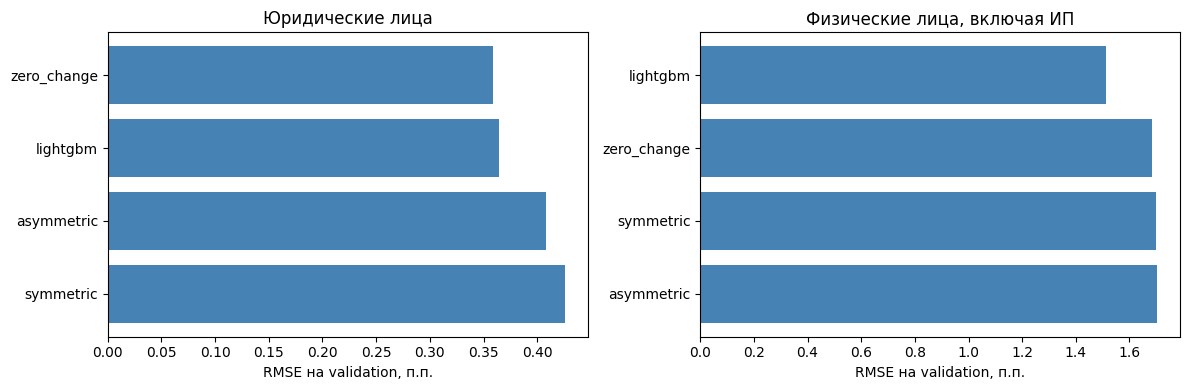

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, group in zip(axes, targets):
    table = (
        comparison[comparison["group"] == group]
        .sort_values("RMSE")
    )

    ax.barh(
        table["model"],
        table["RMSE"],
        color="steelblue"
    )
    ax.invert_yaxis()
    ax.set_title(group_names[group])
    ax.set_xlabel("RMSE на validation, п.п.")

plt.tight_layout()
plt.show()

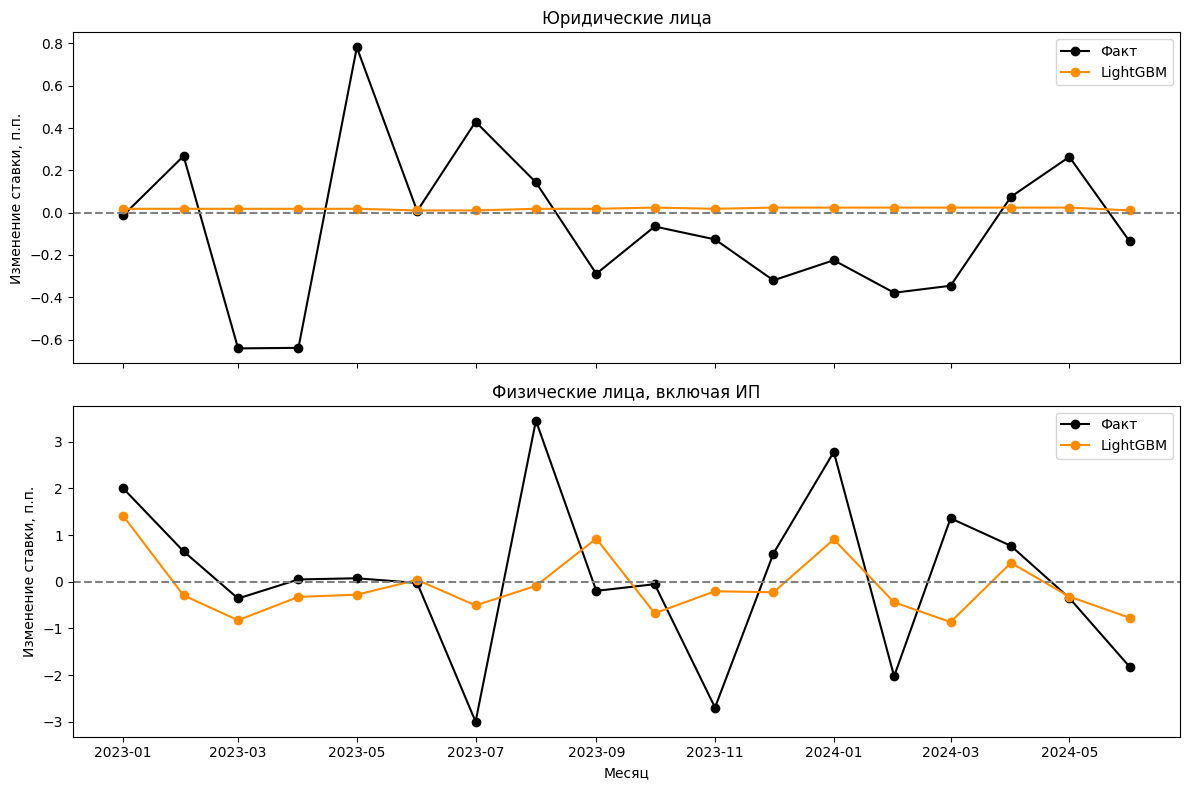

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for ax, group in zip(axes, targets):
    parts = datasets[group]

    ax.plot(
        parts["dates_valid"],
        parts["y_valid"],
        color="black",
        marker="o",
        label="Факт"
    )

    ax.plot(
        parts["dates_valid"],
        predictions[group]["lightgbm"],
        color="darkorange",
        marker="o",
        label="LightGBM"
    )

    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(group_names[group])
    ax.set_ylabel("Изменение ставки, п.п.")
    ax.legend()

axes[1].set_xlabel("Месяц")

plt.tight_layout()
plt.show()

In [21]:
selected_models = {}

for group in targets:
    winner = (
        comparison[comparison["group"] == group]
        .sort_values("RMSE", kind="stable")
        .iloc[0]
    )

    selected_models[group] = str(winner["model"])

    print(
        group_names[group],
        "— выбранная модель:",
        winner["model"]
    )

config = {
    "variant": 6,
    "random_state": RANDOM_STATE,
    "feature_lag_months": FEATURE_LAG,
    "availability_assumption": (
        "Forecast at month start using t-2 or older data; "
        "publication dates not yet verified."
    ),
    "train_end": "2022-12-01",
    "validation_end": "2024-06-01",
    "test_start": "2024-07-01",
    "test_used": False,
    "selection_metric": "validation_RMSE",
    "refit_before_test": False,
    "selected_models": selected_models,
    "baseline_columns": baseline_columns,
    "lightgbm_common_params": common_params,
    "parameter_candidates": parameter_candidates,
    "lightgbm_selected": best_settings,
    "feature_columns": list(
        datasets["business"]["X_train"].columns
    ),
}

Юридические лица — выбранная модель: zero_change
Физические лица, включая ИП — выбранная модель: lightgbm


In [22]:
output_dir = Path("/content/stage3_results")
output_dir.mkdir(exist_ok=True)

with open(output_dir / "config.yaml", "w", encoding="utf-8") as file:
    yaml.safe_dump(
        config, file,
        allow_unicode=True,
        sort_keys=False
    )

comparison.to_csv(
    output_dir / "validation_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

search_results.to_csv(
    output_dir / "parameter_search.csv",
    index=False,
    encoding="utf-8-sig"
)

joblib.dump(
    {
        "baseline_models": baseline_models,
        "boosting_models": boosting_models,
        "config": config,
    },
    output_dir / "stage3_models.joblib"
)

print("Модели, параметры и таблицы сохранены")

Модели, параметры и таблицы сохранены


In [24]:
import importlib.metadata
import shutil
from google.colab import files

packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "statsmodels",
    "scikit-learn",
    "lightgbm",
    "PyYAML",
    "joblib",
]

requirements = "\n".join(
    f"{package}=={importlib.metadata.version(package)}"
    for package in packages
)

(output_dir / "requirements_stage3.txt").write_text(
    requirements + "\n",
    encoding="utf-8"
)

archive = shutil.make_archive(
    "/content/stage3_results",
    "zip",
    root_dir=output_dir
)

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>